<a href="https://colab.research.google.com/github/Yireh111/MachineLearning/blob/main/UnidadII/Proyecto_Unidad_2_SVR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Support Vector Regression (SVR)**

# **Análisis predictivo de la tasa de asesinato**s


- Jaime Alejandro Frayre Salazar
- Gael Yireh Benitez Medina
- Angel Zaid Gamiz Reyes
- Josue Ulises Rios Garcia


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:

df = pd.read_csv("DATASET_Asesinatos.csv", encoding="latin-1")

print("Dataset cargado correctamente")
print("Dimensiones:", df.shape)
display(df.head())

Dataset cargado correctamente
Dimensiones: (3000, 16)


,Estado,id_area,habitantes,area_km2,ingresos_medios,edad_media_poblacion,densidad_poblacional,indice_gini,tasa_desempleo_juvenil,porcentaje_sin_diploma_secundaria,porcentaje_hogares_monoparentales,gasto_policial_per_capita,inversion_programas_sociales_per_capita,tiempo_respuesta_emergencias_min,porcentaje_zonas_verdes,tasa_asesinatos_por_100mil
0,Puebla,1,207953,26.70,48018,40.8,7787.47,0.522,21.8,30.3,40.0,867,240,3.0,5.0,27.1
1,Durango,2,80226,17.39,50295,42.4,4612.66,0.346,19.2,18.9,23.5,706,458,3.0,11.1,13.6
2,Tabasco,3,260806,70.69,50795,39.5,3689.22,0.417,23.0,33.5,23.8,981,403,4.3,8.1,20.6
3,Baja California Sur,4,969508,830.49,68910,27.3,1167.39,0.399,28.8,17.7,23.5,951,326,7.5,16.1,18.5
4,Aguascalientes,5,69478,30.59,54248,36.2,2271.26,0.422,16.4,33.6,27.6,563,353,7.2,10.6,16.8


## Inspección y preparación de los datos

Se revisan los nombres de columnas, tipos de datos, valores faltantes y estadísticas descriptivas. La variable objetivo es tasa_asesinatos_por_100mil.

Para mantener el experimento alineado con las variables iniciales recomendadas en el documento, se utilizarán estas siete predictoras:
- indice_gini
- tasa_desempleo_juvenil
- porcentaje_sin_diploma_secundaria
- ingresos_medios
- densidad_poblacional
- gasto_policial_per_capita
- inversion_programas_sociales_per_capita

No se usan Estado ni id_area como predictores.

In [ ]:
print("Columnas disponibles:")
print(df.columns.tolist())

print("\\nTipos de datos:")
display(df.dtypes.to_frame("tipo_de_dato"))

print("\\nValores faltantes por columna:")
display(df.isna().sum().to_frame("valores_faltantes"))

print("\\nEstadísticas descriptivas:")
display(df.describe(include="all").T)

Columnas disponibles:
['Estado', 'id_area', 'habitantes', 'area_km2', 'ingresos_medios', 'edad_media_poblacion', 'densidad_poblacional', 'indice_gini', 'tasa_desempleo_juvenil', 'porcentaje_sin_diploma_secundaria', 'porcentaje_hogares_monoparentales', 'gasto_policial_per_capita', 'inversion_programas_sociales_per_capita', 'tiempo_respuesta_emergencias_min', 'porcentaje_zonas_verdes', 'tasa_asesinatos_por_100mil']
\nTipos de datos:


,tipo_de_dato
Estado,object
id_area,int64
habitantes,int64
area_km2,float64
ingresos_medios,int64
edad_media_poblacion,float64
densidad_poblacional,float64
indice_gini,float64
tasa_desempleo_juvenil,float64
porcentaje_sin_diploma_secundaria,float64


\nValores faltantes por columna:


,valores_faltantes
Estado,0
id_area,0
habitantes,0
area_km2,0
ingresos_medios,0
edad_media_poblacion,0
densidad_poblacional,0
indice_gini,0
tasa_desempleo_juvenil,0
porcentaje_sin_diploma_secundaria,0


\nEstadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Estado,3000,32,Querétaro,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_area,3000.0,NaN,NaN,NaN,1500.5,866.169729,1.0,750.75,1500.5,2250.25,3000.0
habitantes,3000.0,NaN,NaN,NaN,262654.719333,413727.48148,5000.0,38510.0,102389.5,271138.5,2000000.0
area_km2,3000.0,NaN,NaN,NaN,96.967677,172.700026,10.0,12.125,33.96,96.0575,2207.18
ingresos_medios,3000.0,NaN,NaN,NaN,60298.995333,13220.705234,30000.0,51384.75,58931.0,67677.25,121378.0
edad_media_poblacion,3000.0,NaN,NaN,NaN,36.915533,4.859472,25.0,33.6,36.9,40.2,53.9
densidad_poblacional,3000.0,NaN,NaN,NaN,2991.633247,1711.261226,500.0,1814.545,2656.71,3773.4425,14640.99
indice_gini,3000.0,NaN,NaN,NaN,0.422485,0.052641,0.253,0.387,0.422,0.458,0.63
tasa_desempleo_juvenil,3000.0,NaN,NaN,NaN,19.637433,4.976529,5.6,16.1,19.7,23.2,30.0
porcentaje_sin_diploma_secundaria,3000.0,NaN,NaN,NaN,25.1231,9.91225,5.0,18.1,24.9,32.0,50.0


In [ ]:
objetivo = "tasa_asesinatos_por_100mil"

variables_iniciales = [
    "indice_gini",
    "tasa_desempleo_juvenil",
    "porcentaje_sin_diploma_secundaria",
    "ingresos_medios",
    "densidad_poblacional",
    "gasto_policial_per_capita",
    "inversion_programas_sociales_per_capita",
]

columnas_necesarias = variables_iniciales + [objetivo]
faltantes_columnas = [col for col in columnas_necesarias if col not in df.columns]
if faltantes_columnas:
    raise ValueError(f"Faltan columnas necesarias en el CSV: {faltantes_columnas}")

datos = df[columnas_necesarias].copy()

# Convertir a valores numéricos y marcar como NaN cualquier dato no convertible.
for col in columnas_necesarias:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

filas_antes = len(datos)
datos = datos.replace([np.inf, -np.inf], np.nan).dropna()
filas_eliminadas = filas_antes - len(datos)

X = datos[variables_iniciales]
y = datos[objetivo]

print(f"Filas originales: {filas_antes}")
print(f"Filas eliminadas por valores faltantes/no numéricos: {filas_eliminadas}")
print(f"Filas finales para el modelado: {len(datos)}")
print(f"Número de variables predictoras: {X.shape[1]}")
display(X.head())

Filas originales: 3000
Filas eliminadas por valores faltantes/no numéricos: 0
Filas finales para el modelado: 3000
Número de variables predictoras: 7


,indice_gini,tasa_desempleo_juvenil,porcentaje_sin_diploma_secundaria,ingresos_medios,densidad_poblacional,gasto_policial_per_capita,inversion_programas_sociales_per_capita
0,0.522,21.8,30.3,48018,7787.47,867,240
1,0.346,19.2,18.9,50295,4612.66,706,458
2,0.417,23.0,33.5,50795,3689.22,981,403
3,0.399,28.8,17.7,68910,1167.39,951,326
4,0.422,16.4,33.6,54248,2271.26,563,353


## Exploración visual

Estas visualizaciones permiten observar la distribución de la variable objetivo y las correlaciones lineales entre las variables numéricas. Las correlaciones son descriptivas y no implican causalidad.

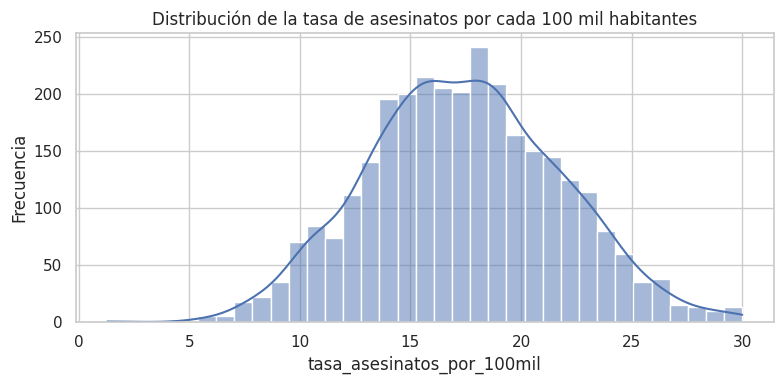

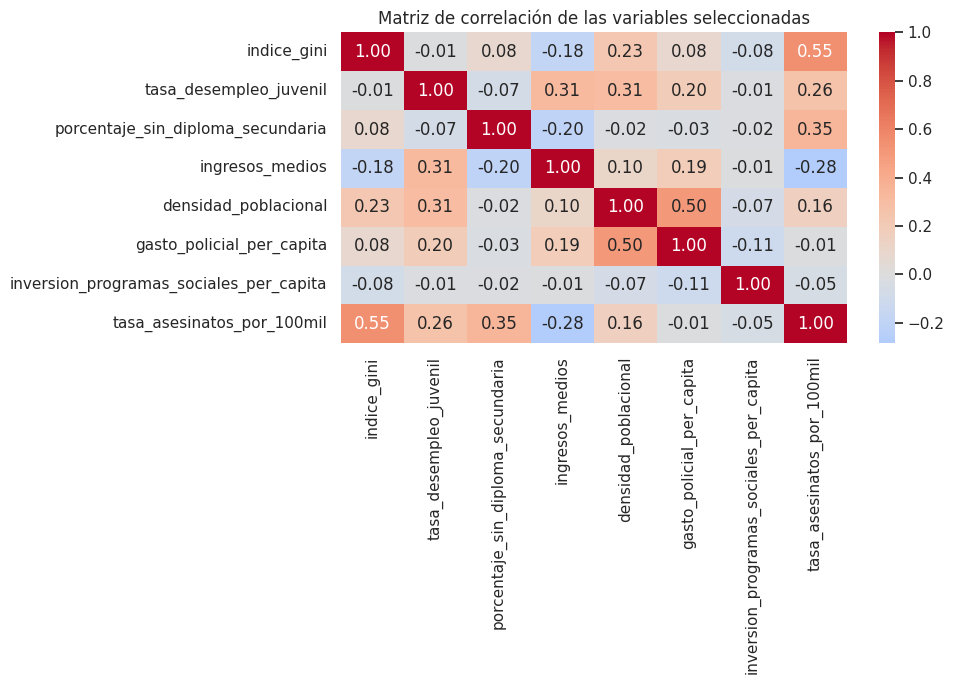

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(y, kde=True)
plt.title("Distribución de la tasa de asesinatos por cada 100 mil habitantes")
plt.xlabel(objetivo)
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
correlaciones = datos.corr(numeric_only=True)
sns.heatmap(correlaciones, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Matriz de correlación de las variables seleccionadas")
plt.tight_layout()
plt.show()

## Separar los datos en entrenamiento y prueba

Se reserva el 20 % de los datos para prueba y se utiliza el 80 % restante para entrenamiento. Se fija random_state=42.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (2400, 7)
X_test:  (600, 7)
y_train: (2400,)
y_test:  (600,)


## Función para entrenar y evaluar SVR

Se calcularán:
- R²
- MAE
- RMSE

Los modelos se evalúan con los mismos datos de entrenamiento y prueba para que la comparación entre kernels sea justa.

In [ ]:
def entrenar_evaluar_svr(nombre, kernel, C=1.0, epsilon=0.1, degree=3):
    modelo = Pipeline(steps=[
        ("escalador", StandardScaler()),
        ("svr", SVR(kernel=kernel, C=C, epsilon=epsilon, degree=degree))
    ])

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados = {
        "Modelo": nombre,
        "Kernel": kernel,
        "C": C,
        "epsilon": epsilon,
        "R2_entrenamiento": r2_score(y_train, pred_train),
        "R2_prueba": r2_score(y_test, pred_test),
        "MAE_prueba": mean_absolute_error(y_test, pred_test),
        "RMSE_prueba": np.sqrt(mean_squared_error(y_test, pred_test)),
    }

    return modelo, pred_test, resultados

## Ejecución 1 — SVR con kernel RBF

RBF es el kernel predeterminado de SVR y puede representar relaciones no lineales. Se inicia con los parámetros habituales C=1.0 y epsilon=0.1.

In [ ]:
svr_rbf, pred_rbf, resultados_rbf = entrenar_evaluar_svr(
    nombre="SVR RBF",
    kernel="rbf",
    C=1.0,
    epsilon=0.1
)

display(pd.DataFrame([resultados_rbf]).round(4))

,Modelo,Kernel,C,epsilon,R2_entrenamiento,R2_prueba,MAE_prueba,RMSE_prueba
0,SVR RBF,rbf,1.0,0.1,0.5463,0.5166,2.5053,3.122


## Ejecución 2 — SVR con kernel lineal

El kernel lineal modela una relación lineal en el espacio de las variables transformadas. Se conservan los mismos datos, partición y valores de C y epsilon; así, la principal diferencia entre las dos ejecuciones es el kernel.

In [ ]:
svr_linear, pred_linear, resultados_linear = entrenar_evaluar_svr(
    nombre="SVR Linear",
    kernel="linear",
    C=1.0,
    epsilon=0.1
)

display(pd.DataFrame([resultados_linear]).round(4))

,Modelo,Kernel,C,epsilon,R2_entrenamiento,R2_prueba,MAE_prueba,RMSE_prueba
0,SVR Linear,linear,1.0,0.1,0.5332,0.5554,2.4266,2.9942


## Comparación de las dos ejecuciones SVR


In [ ]:
resultados = pd.DataFrame([resultados_rbf, resultados_linear])
resultados = resultados.sort_values("R2_prueba", ascending=False).reset_index(drop=True)
display(resultados.round(4))

mejor = resultados.iloc[0]
print(
    f"Según el R² de prueba, el mejor resultado de estas dos ejecuciones fue "
    f"{mejor['Modelo']} (R² prueba = {mejor['R2_prueba']:.4f})."
)

,Modelo,Kernel,C,epsilon,R2_entrenamiento,R2_prueba,MAE_prueba,RMSE_prueba
0,SVR Linear,linear,1.0,0.1,0.5332,0.5554,2.4266,2.9942
1,SVR RBF,rbf,1.0,0.1,0.5463,0.5166,2.5053,3.1220


Según el R² de prueba, el mejor resultado de estas dos ejecuciones fue SVR Linear (R² prueba = 0.5554).


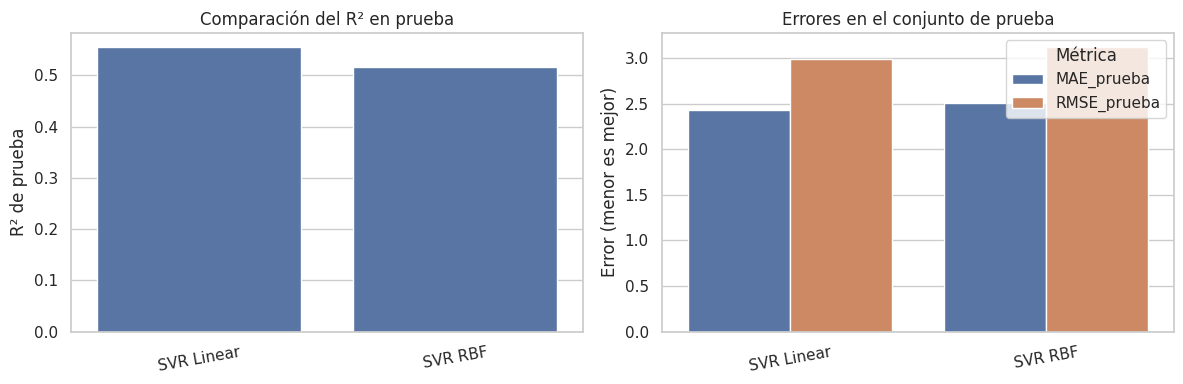

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=resultados, x="Modelo", y="R2_prueba", ax=axes[0])
axes[0].set_title("Comparación del R² en prueba")
axes[0].set_xlabel("")
axes[0].set_ylabel("R² de prueba")
axes[0].tick_params(axis="x", rotation=10)

metricas_largas = resultados.melt(
    id_vars="Modelo",
    value_vars=["MAE_prueba", "RMSE_prueba"],
    var_name="Métrica",
    value_name="Error"
)
sns.barplot(data=metricas_largas, x="Modelo", y="Error", hue="Métrica", ax=axes[1])
axes[1].set_title("Errores en el conjunto de prueba")
axes[1].set_xlabel("")
axes[1].set_ylabel("Error (menor es mejor)")
axes[1].tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

## Gráficas: valores reales frente a predicciones

Si las predicciones fueran perfectas, los puntos caerían sobre la diagonal. Las distancias respecto a la diagonal muestran los errores de predicción.

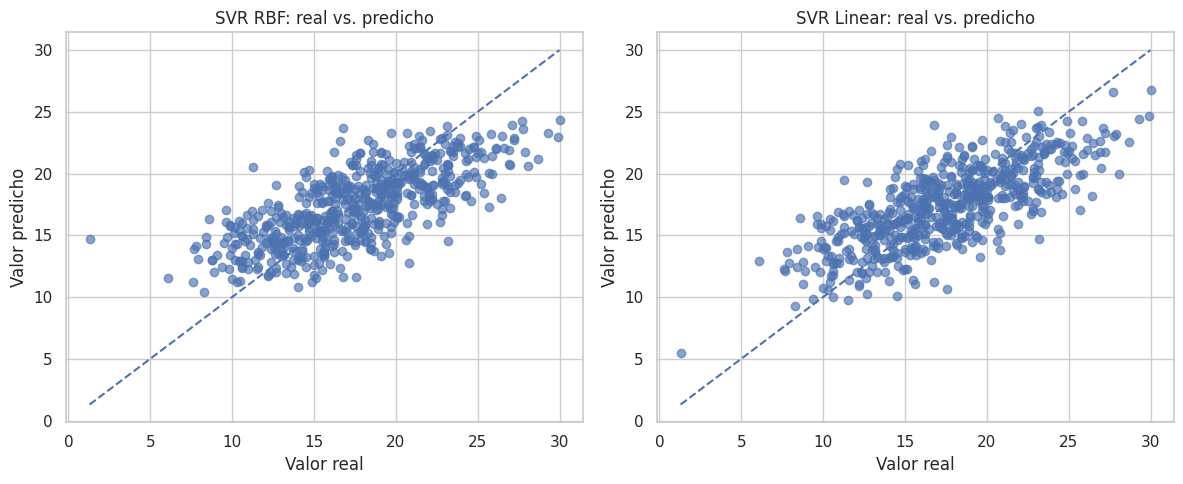

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
predicciones = [
    ("SVR RBF", pred_rbf, axes[0]),
    ("SVR Linear", pred_linear, axes[1]),
]

min_val = min(float(y_test.min()), float(np.min(pred_rbf)), float(np.min(pred_linear)))
max_val = max(float(y_test.max()), float(np.max(pred_rbf)), float(np.max(pred_linear)))

for nombre, pred, ax in predicciones:
    ax.scatter(y_test, pred, alpha=0.65)
    ax.plot([min_val, max_val], [min_val, max_val], linestyle="--")
    ax.set_title(f"{nombre}: real vs. predicho")
    ax.set_xlabel("Valor real")
    ax.set_ylabel("Valor predicho")

plt.tight_layout()
plt.show()

# Conclusiones


**Mejor Rendimiento:** ¿Qué algoritmo arrojó el valor de (R
2
) más alto en el conjunto de
prueba? ¿A qué cree que se debe su superioridad?

El algoritmo con el R² de prueba más alto fue SVR con **kernel lineal (R² = 0.5554)**, frente a SVR **RBF (R² = 0.5166)**. También tuvo menores errores: **MAE de 2.4266 contra 2.5053** y **RMSE de 2.9942 contra 3.1220**.

Por qué es superior:

- La relación entre los predictores y la tasa de asesinatos parece ser sobre todo lineal. El kernel RBF añade flexibilidad que no hace falta y generaliza peor.
- El SVR lineal es más estable: su** R² de entrenamiento (0.5332)** y su **R² de prueba (0.5554)** son casi iguales, así que no sobreajusta. El RBF sí muestra una pequeña brecha, con** 0.5463 en entrenamiento** y **0.5166 en prueba**.
- Los datos se estandarizaron con **StandardScaler** y ambos modelos usaron los mismos parámetros **(C = 1.0, epsilon = 0.1)**. La diferencia viene del kernel y no de otra configuración.

**Recomendación de Modelo:** Si el objetivo del proyecto fuera **convencer al gobierno**
de invertir en un programa social específico, ¿qué tipo de modelo recomendaría utilizar
para respaldar su argumento y por qué?

Se recomendaría un modelo lineal interpretable, es decir, el **SVR lineal**. Las razones son estas:

- **Interpretabilidad:** los coeficientes muestran cuánto cambia la tasa de asesinatos por cada unidad de variable. Por ejemplo, se puede ver el efecto de inversion_programas_sociales_per_capita manteniendo constantes las demás variables. Es un argumento directo para quien toma decisiones.
- **Transparencia:** un modelo que se explica en una frase es más fácil de defender ante un gobierno que una caja negra como RBF o XGBoost.
- **Rendimiento suficiente:** el SVR lineal superó al RBF (0.5554 contra 0.5166). Eso indica que la complejidad adicional no mejoró la predicción.
- **Precaución:** el modelo muestra asociaciones y no causalidad, y el propio notebook lo aclara en la sección de exploración. Conviene decirlo al presentar el argumento.